In [1]:
import matplotlib.pyplot as plt
import nbimporter
import numpy as np
import pandas as pd
from apex_arrow import p_apex_arrow2
from ffxiv_stats import Rotation
from mages_ballad import p_hs
from matplotlib.ticker import FuncFormatter
from refulgent_arrow import p_refulgent
from wanderers_minuet import joint_pp3_prob

# from mages_ballad import
from shared import (
    BARD_RATE,
    convolve_sequences,
    mixture_distribution,
    pmf_mean,
    pmf_std,
    relative_d2,
    set_custom_style,
)

# Set custom plot style
set_custom_style()

['#5842ff', '#ff4000', '#00b368']

In [2]:
time = 120

In [3]:
print("Iron Jaws", relative_d2(100))
print("Empyreal Arrow", relative_d2(260))
print("Radiant Encore", relative_d2(900))
print("Resonant Arrow", relative_d2(600))
print("Sidewinder", relative_d2(400))
print("Stormbite", relative_d2(25))
print("Caustic Bite", relative_d2(20))
print("Auto", relative_d2(80))
80

Iron Jaws 4545
Empyreal Arrow 11818
Radiant Encore 40909
Resonant Arrow 27272
Sidewinder 18181
Stormbite 1136
Caustic Bite 909
Auto 3636


80

In [4]:
def refulgent_most_probable(n):
    return int(np.argmax([p_refulgent(n, k) for k in range(n)]))


for n in [1, 2, 3, 6, 14, 17, 44]:
    print(f"n = {n:02d}, most probable refulgent_count:", refulgent_most_probable(n))

n = 01, most probable refulgent_count: 0
n = 02, most probable refulgent_count: 1
n = 03, most probable refulgent_count: 1
n = 06, most probable refulgent_count: 2
n = 14, most probable refulgent_count: 4
n = 17, most probable refulgent_count: 5
n = 44, most probable refulgent_count: 12


In [5]:
def make_ra_entry(n):
    return rf"$\sim RA(n={n})$"


def make_bs_entry(n, subtract_ij=False):
    ij_string = " - 1" if subtract_ij else ""
    return rf"${n} - K_{{ra}}{ij_string}, \textrm{{where}} K_{{ra}} \sim RA(n={n})$"


print(make_ra_entry(2))
print(make_bs_entry(2, False))
print()
print(make_ra_entry(1))
print(make_bs_entry(1, False))
print()
print(make_ra_entry(3))
print(make_bs_entry(3, True))
print()
print(make_ra_entry(1))
print(make_bs_entry(1, False))
print()
print(make_ra_entry(6))
print(make_bs_entry(6, False))
print()
print(make_ra_entry(14))
print(make_bs_entry(14, True))
print()
print(make_ra_entry(17))
print(make_bs_entry(17, True))

$\sim RA(n=2)$
$2 - K_{ra}, \textrm{where} K_{ra} \sim RA(n=2)$

$\sim RA(n=1)$
$1 - K_{ra}, \textrm{where} K_{ra} \sim RA(n=1)$

$\sim RA(n=3)$
$3 - K_{ra} - 1, \textrm{where} K_{ra} \sim RA(n=3)$

$\sim RA(n=1)$
$1 - K_{ra}, \textrm{where} K_{ra} \sim RA(n=1)$

$\sim RA(n=6)$
$6 - K_{ra}, \textrm{where} K_{ra} \sim RA(n=6)$

$\sim RA(n=14)$
$14 - K_{ra} - 1, \textrm{where} K_{ra} \sim RA(n=14)$

$\sim RA(n=17)$
$17 - K_{ra} - 1, \textrm{where} K_{ra} \sim RA(n=17)$


## Full rotation

Split it up into sections to make it more easily reusable

### WM

In [6]:
def make_action_record(
    n: int,
    d: int,
    base_action: str,
    buff_str: str,
    p: list[int],
    l_c: int,
    multiplier: float,
    dot: bool,
):
    return {
        "n": n,
        "d2": d,
        "action_name": f"{base_action}-{buff_str}",
        "base_action": base_action,
        "p_n": p[0],
        "p_c": p[1],
        "p_d": p[2],
        "p_cd": p[3],
        "l_c": l_c,
        "buffs": multiplier,
        "is_dot": dot,
    }

In [7]:
wm_1_mode = [
    make_action_record(
        1,
        12727,
        "Refulgent Arrow",
        "wm",
        BARD_RATE.get_p(ch_mod=0.02),
        BARD_RATE.l_c,
        1.0,
        False,
    ),
    make_action_record(
        1,
        10000,
        "Burst Shot",
        "wm",
        BARD_RATE.get_p(ch_mod=0.02),
        BARD_RATE.l_c,
        1.0,
        False,
    ),
]

wm_2_constants = [
    make_action_record(
        1,
        3636,
        "Attack",
        "wm_bv_rf",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06,
        False,
    ),
    make_action_record(
        1,
        8181,
        "Heartbreak Shot",
        "wm_bv_rf",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06,
        False,
    ),
]

wm_2_mode = [
    make_action_record(
        1,
        10000,
        "Burst Shot",
        "wm_bv_rf",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06,
        False,
    ),
]

In [8]:
wm_3_constants = [
    make_action_record(
        6,
        3636,
        "Attack",
        "wm_bv_rf_rs",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06 * 1.15,
        False,
    ),
    make_action_record(
        3,
        8181,
        "Heartbreak Shot",
        "wm_bv_rf_rs",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06 * 1.15,
        False,
    ),
    make_action_record(
        2,
        11818,
        "Empyreal Arrow",
        "wm_bv_rf_rs",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06 * 1.15,
        False,
    ),
    make_action_record(
        1,
        27272,
        "Blast Arrow",
        "wm_bv_rf_rs",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06 * 1.15,
        False,
    ),
    make_action_record(
        1,
        4545,
        "Iron Jaws",
        "wm_bv_rf_rs",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06 * 1.15,
        False,
    ),
    make_action_record(
        1,
        40909,
        "Radiant Encore (3)",
        "wm_bv_rf_rs",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06 * 1.15,
        False,
    ),
    make_action_record(
        1,
        27272,
        "Resonant Arrow",
        "wm_bv_rf_rs",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06 * 1.15,
        False,
    ),
    make_action_record(
        1,
        18181,
        "Sidewinder",
        "wm_bv_rf_rs",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06 * 1.15,
        False,
    ),
    # Guaranteed 3x from barrage
    make_action_record(
        3,
        12727,
        "Refulgent Arrow",
        "wm_bv_rf_rs",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06 * 1.15,
        False,
    ),
    make_action_record(
        15,
        1136,
        "Stormbite (tick)",
        "wm_bv_rf_rs",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06 * 1.15,
        True,
    ),
    make_action_record(
        15,
        909,
        "Caustic Bite (tick)",
        "wm_bv_rf_rs",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06 * 1.15,
        True,
    ),
]

wm_3_mode = [
    make_action_record(
        1,
        10000,
        "Burst Shot",
        "wm_bv_rf_rs",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06 * 1.15,
        False,
    ),
    make_action_record(
        3,
        16363,
        "Pitch Perfect (3)",
        "wm_bv_rf_rs",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06 * 1.15,
        False,
    ),
    make_action_record(
        1,
        27272,
        "Apex Arrow",
        "wm_bv_rf_rs",
        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
        BARD_RATE.l_c,
        1.06 * 1.15,
        False,
    ),
]
display(pd.DataFrame(wm_3_constants))
pd.DataFrame(wm_3_mode)

,n,d2,action_name,base_action,p_n,p_c,p_d,p_cd,l_c,buffs,is_dot
0,6,3636,Attack-wm_bv_rf_rs,Attack,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
1,3,8181,Heartbreak Shot-wm_bv_rf_rs,Heartbreak Shot,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
2,2,11818,Empyreal Arrow-wm_bv_rf_rs,Empyreal Arrow,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
3,1,27272,Blast Arrow-wm_bv_rf_rs,Blast Arrow,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
4,1,4545,Iron Jaws-wm_bv_rf_rs,Iron Jaws,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
5,1,40909,Radiant Encore (3)-wm_bv_rf_rs,Radiant Encore (3),0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
6,1,27272,Resonant Arrow-wm_bv_rf_rs,Resonant Arrow,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
7,1,18181,Sidewinder-wm_bv_rf_rs,Sidewinder,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
8,3,12727,Refulgent Arrow-wm_bv_rf_rs,Refulgent Arrow,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
9,15,1136,Stormbite (tick)-wm_bv_rf_rs,Stormbite (tick),0.36356,0.12444,0.38144,0.13056,1585.0,1.219,True


,n,d2,action_name,base_action,p_n,p_c,p_d,p_cd,l_c,buffs,is_dot
0,1,10000,Burst Shot-wm_bv_rf_rs,Burst Shot,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
1,3,16363,Pitch Perfect (3)-wm_bv_rf_rs,Pitch Perfect (3),0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
2,1,27272,Apex Arrow-wm_bv_rf_rs,Apex Arrow,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False


In [9]:
wm_4_mode = [
    make_action_record(
        1,
        10000,
        "Burst Shot",
        "wm_rs",
        BARD_RATE.get_p(ch_mod=0.02),
        BARD_RATE.l_c,
        1.15,
        False,
    ),
]

wm_5_constants = [
    make_action_record(
        5,
        3636,
        "Attack",
        "wm",
        BARD_RATE.get_p(ch_mod=0.02),
        BARD_RATE.l_c,
        1.0,
        False,
    ),
    make_action_record(
        1,
        8181,
        "Heartbreak Shot",
        "wm",
        BARD_RATE.get_p(ch_mod=0.02),
        BARD_RATE.l_c,
        1.0,
        False,
    ),
    make_action_record(
        1,
        11818,
        "Empyreal Arrow",
        "wm",
        BARD_RATE.get_p(ch_mod=0.02),
        BARD_RATE.l_c,
        1.0,
        False,
    ),
]

wm_5_mode = [
    make_action_record(
        2,
        16363,
        "Pitch Perfect (3)",
        "wm",
        BARD_RATE.get_p(ch_mod=0.02),
        BARD_RATE.l_c,
        1.0,
        False,
    ),
    make_action_record(
        2,
        12727,
        "Refulgent Arrow",
        "wm",
        BARD_RATE.get_p(ch_mod=0.02),
        BARD_RATE.l_c,
        1.0,
        False,
    ),
    make_action_record(
        4,
        10000,
        "Burst Shot",
        "wm",
        BARD_RATE.get_p(ch_mod=0.02),
        BARD_RATE.l_c,
        1.0,
        False,
    ),
]

### MB

In [10]:
mb_constants = [
    make_action_record(
        13,
        3636,
        "Attack",
        "mb",
        BARD_RATE.get_p(),
        BARD_RATE.l_c,
        1.01,
        False,
    ),
    make_action_record(
        1,
        4545,
        "Iron Jaws",
        "mb",
        BARD_RATE.get_p(),
        BARD_RATE.l_c,
        1.01,
        False,
    ),
    make_action_record(
        2,
        11818,
        "Empyreal Arrow",
        "mb",
        BARD_RATE.get_p(),
        BARD_RATE.l_c,
        1.01,
        False,
    ),
    make_action_record(
        1,
        18181,
        "Sidewinder",
        "mb",
        BARD_RATE.get_p(),
        BARD_RATE.l_c,
        1.01,
        False,
    ),
    make_action_record(
        1,
        27272,
        "Blast Arrow",
        "mb",
        BARD_RATE.get_p(),
        BARD_RATE.l_c,
        1.01,
        False,
    ),
    # Guaranteed HS
    make_action_record(
        3,
        8181,
        "Heartbreak Shot",
        "mb",
        BARD_RATE.get_p(),
        BARD_RATE.l_c,
        1.01,
        False,
    ),
    make_action_record(
        10,
        1136,
        "Stormbite (tick)",
        "mb",
        BARD_RATE.get_p(),
        BARD_RATE.l_c,
        1.01,
        True,
    ),
    make_action_record(
        10,
        909,
        "Caustic Bite (tick)",
        "mb",
        BARD_RATE.get_p(),
        BARD_RATE.l_c,
        1.01,
        True,
    ),
]

mb_mode = [
    make_action_record(
        4,
        12727,
        "Refulgent Arrow",
        "mb",
        BARD_RATE.get_p(),
        BARD_RATE.l_c,
        1.01,
        False,
    ),
    make_action_record(
        9,
        10000,
        "Burst Shot",
        "mb",
        BARD_RATE.get_p(),
        BARD_RATE.l_c,
        1.01,
        False,
    ),
    make_action_record(
        1,
        27272,
        "Apex Arrow",
        "mb",
        BARD_RATE.get_p(),
        BARD_RATE.l_c,
        1.01,
        False,
    ),
    make_action_record(
        6,
        8181,
        "Heartbreak Shot",
        "mb",
        BARD_RATE.get_p(),
        BARD_RATE.l_c,
        1.01,
        False,
    ),
]

### AP

In [11]:
ap_constants = [
    make_action_record(
        1,
        4545,
        "Iron Jaws",
        "ap",
        BARD_RATE.get_p(dh_mod=0.03),
        BARD_RATE.l_c,
        1.0,
        False,
    ),
    make_action_record(
        14,
        3636,
        "Attack",
        "ap",
        BARD_RATE.get_p(dh_mod=0.03),
        BARD_RATE.l_c,
        1.0,
        False,
    ),
    make_action_record(
        3,
        11818,
        "Empyreal Arrow",
        "ap",
        BARD_RATE.get_p(dh_mod=0.03),
        BARD_RATE.l_c,
        1.0,
        False,
    ),
    make_action_record(
        3,
        8181,
        "Heartbreak Shot",
        "ap",
        BARD_RATE.get_p(dh_mod=0.03),
        BARD_RATE.l_c,
        1.0,
        False,
    ),
    make_action_record(
        3,
        1136,
        "Stormbite (tick)",
        "ap",
        BARD_RATE.get_p(dh_mod=0.03),
        BARD_RATE.l_c,
        1.0,
        True,
    ),
    make_action_record(
        3,
        909,
        "Caustic Bite (tick)",
        "ap",
        BARD_RATE.get_p(dh_mod=0.03),
        BARD_RATE.l_c,
        1.0,
        True,
    ),
]

ap_mode = [
    make_action_record(
        11,
        10000,
        "Burst Shot",
        "ap",
        BARD_RATE.get_p(dh_mod=0.03),
        BARD_RATE.l_c,
        1.0,
        False,
    ),
    make_action_record(
        5,
        12727,
        "Refulgent Arrow",
        "ap",
        BARD_RATE.get_p(dh_mod=0.03),
        BARD_RATE.l_c,
        1.0,
        False,
    ),
]

In [12]:
deterministic_records = (
    wm_2_constants + wm_3_constants + wm_5_constants + mb_constants + ap_constants
)

stochastic_mode_records = (
    wm_1_mode + wm_2_mode + wm_3_mode + wm_4_mode + wm_5_mode + mb_mode + ap_mode
)

mode_df = pd.DataFrame(deterministic_records + stochastic_mode_records).sort_values(
    ["base_action", "n", "d2"], ascending=[True, False, False]
)

time = 120

mode_rotation = Rotation(mode_df, time, 1, 1, 1, 1)

mode_df

# deterministic_rotation.sort_values(
#     ["base_action", "n", "d2"], ascending=[True, False, False]
# )


,n,d2,action_name,base_action,p_n,p_c,p_d,p_cd,l_c,buffs,is_dot
35,1,27272,Apex Arrow-wm_bv_rf_rs,Apex Arrow,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
42,1,27272,Apex Arrow-mb,Apex Arrow,0.52632,0.16168,0.23868,0.07332,1585.0,1.010,False
25,14,3636,Attack-ap,Attack,0.50337,0.15463,0.26163,0.08037,1585.0,1.000,False
16,13,3636,Attack-mb,Attack,0.52632,0.16168,0.23868,0.07332,1585.0,1.010,False
2,6,3636,Attack-wm_bv_rf_rs,Attack,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
13,5,3636,Attack-wm,Attack,0.51256,0.17544,0.23244,0.07956,1585.0,1.000,False
0,1,3636,Attack-wm_bv_rf,Attack,0.36356,0.12444,0.38144,0.13056,1585.0,1.060,False
5,1,27272,Blast Arrow-wm_bv_rf_rs,Blast Arrow,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
20,1,27272,Blast Arrow-mb,Blast Arrow,0.52632,0.16168,0.23868,0.07332,1585.0,1.010,False
44,11,10000,Burst Shot-ap,Burst Shot,0.50337,0.15463,0.26163,0.08037,1585.0,1.000,False


## Proc variability analysis

In [13]:
def make_rotation_list(rotation_df_list, time):
    return [Rotation(r, time, 1, 1, 1, 1) for r in rotation_df_list]

### Refulgent arrow



In [14]:
def refulgent_arrow_rotations(
    n: int, buff_str: str, p: list[float], multiplier: float, ij_subtract: bool = False
):
    offset = 1 if ij_subtract else 0
    w = []
    rotation_df_list = []

    for k_ra in range(0, (n + 1) // 2 + 1):
        record_list = []
        k_bs = n - k_ra - offset

        if k_bs > 0:
            record_list.append(
                make_action_record(
                    k_bs,
                    10000,
                    "Burst Shot",
                    buff_str,
                    p,
                    BARD_RATE.l_c,
                    multiplier,
                    False,
                )
            )

        if k_ra > 0:
            record_list.append(
                make_action_record(
                    k_ra,
                    12727,
                    "Refulgent Arrow",
                    buff_str,
                    p,
                    BARD_RATE.l_c,
                    multiplier,
                    False,
                )
            )

        if len(record_list) > 0:
            w.append(p_refulgent(n, k_ra))
            rotation_df_list.append(pd.DataFrame(record_list))
        pass
    return rotation_df_list, w

In [15]:
wm_1_ra_df, wm_1_ra_w = refulgent_arrow_rotations(
    2, "wm", BARD_RATE.get_p(ch_mod=0.02), 1.0, False
)
wm_2_ra_df, wm_2_ra_w = refulgent_arrow_rotations(
    1, "wm_bv_rf", BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2), 1.06, False
)
wm_3_ra_df, wm_3_ra_w = refulgent_arrow_rotations(
    2, "wm_bv_rf_rs", BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2), 1.06 * 1.15, False
)
wm_4_ra_df, wm_4_ra_w = refulgent_arrow_rotations(
    1, "wm_rs", BARD_RATE.get_p(ch_mod=0.02), 1.15, False
)
wm_5_ra_df, wm_5_ra_w = refulgent_arrow_rotations(
    6, "wm", BARD_RATE.get_p(ch_mod=0.02), 1.0, False
)

mb_ra_df, mb_ra_w = refulgent_arrow_rotations(14, "mb", BARD_RATE.p, 1.01, True)

ap_ra_df, ap_ra_w = refulgent_arrow_rotations(
    17, "ap", BARD_RATE.get_p(dh_mod=0.03), 1.0, True
)


In [16]:
wm_1_ra_rotation = make_rotation_list(wm_1_ra_df, time)
wm_2_ra_rotation = make_rotation_list(wm_2_ra_df, time)
wm_3_ra_rotation = make_rotation_list(wm_3_ra_df, time)
wm_4_ra_rotation = make_rotation_list(wm_4_ra_df, time)
wm_5_ra_rotation = make_rotation_list(wm_5_ra_df, time)

mb_ra_rotation = make_rotation_list(mb_ra_df, time)
ap_ra_rotation = make_rotation_list(ap_ra_df, time)

ra_pmf, ra_supp = convolve_sequences(
    [
        mixture_distribution(wm_1_ra_rotation, wm_1_ra_w),
        mixture_distribution(wm_2_ra_rotation, wm_2_ra_w),
        mixture_distribution(wm_3_ra_rotation, wm_3_ra_w),
        mixture_distribution(wm_4_ra_rotation, wm_4_ra_w),
        mixture_distribution(wm_5_ra_rotation, wm_5_ra_w),
        mixture_distribution(mb_ra_rotation, mb_ra_w),
        mixture_distribution(ap_ra_rotation, ap_ra_w),
    ]
)


In [17]:
# Ad hoc, add in 3
barrage_refulgent = Rotation(
    pd.DataFrame(
        [
            make_action_record(
                3,
                12727,
                "Refulgent Arrow",
                "wm_bv_rf_rs",
                BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
                BARD_RATE.l_c,
                1.06 * 1.15,
                False,
            )
        ]
    ),
    time,
    1,
    1,
    1,
    1,
)

(4200.0, 6200.0)

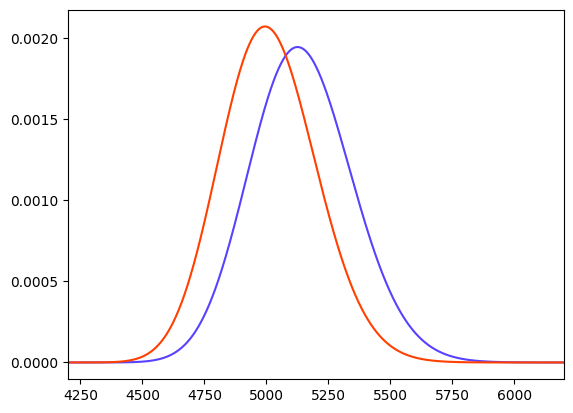

In [18]:
hara_y, hara_x = convolve_sequences(
    [
        (ra_pmf, ra_supp),
        (
            barrage_refulgent.rotation_dps_distribution,
            barrage_refulgent.rotation_dps_support,
        ),
    ]
)
y_hara_mode, x_hara_mode = convolve_sequences(
    [
        (mode_rotation.action_dps_distributions[i], mode_rotation.action_dps_support[i])
        for i in mode_rotation.unique_actions["Burst Shot"]
        + mode_rotation.unique_actions["Refulgent Arrow"]
    ]
)
plt.plot(hara_x, hara_y)
plt.plot(x_hara_mode, y_hara_mode)
plt.xlim([4200, 6200])

### PP3

In [19]:
def make_pp3_rotations(time: int, n_r_b: int = 8, n_r_nb: int = 7):
    rotations = []
    w = []
    for i in range(4):
        for j in range(4):
            records = []

            # Ignore when there are no usages, ffxiv_stats doesn't like that
            if i > 0:
                records.append(
                    make_action_record(
                        i,
                        16363,
                        "Pitch Perfect (3)",
                        "wm_bv_rf_rs",
                        BARD_RATE.get_p(ch_mod=0.02, dh_mod=0.2),
                        BARD_RATE.l_c,
                        1.15 * 1.06,
                        False,
                    )
                )
            if j > 0:
                records.append(
                    make_action_record(
                        j,
                        16363,
                        "Pitch Perfect (3)",
                        "wm",
                        BARD_RATE.get_p(ch_mod=0.02),
                        BARD_RATE.l_c,
                        1.0,
                        False,
                    )
                )

            # Final PP1 leftover, except for i = 3, j = 3
            # if (i + j > 0) & (i + j < 6):
            #     records.append(make_pp1_no_burst_record(r.get_p(0.02), r.l_c))
            if len(records) > 0:
                # print(records)
                # print(i, j)
                rotation_df = pd.DataFrame(records)
                rotations.append(Rotation(rotation_df, time, 1, 1, 1, 1))
                w.append(joint_pp3_prob(i, j, n_r_b, n_r_nb))

    return rotations, w

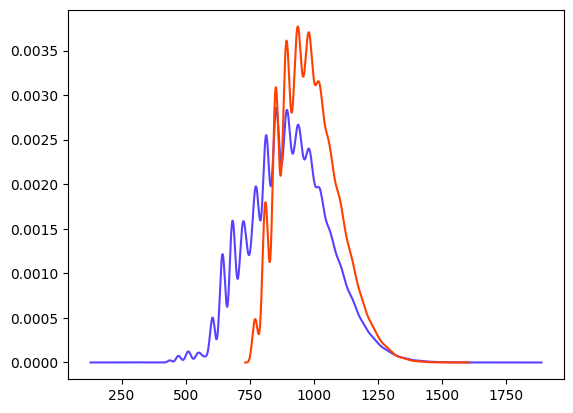

In [20]:
pp3_rotations, pp3_w = make_pp3_rotations(time)

pp3_pmf, pp3_support = mixture_distribution(pp3_rotations, pp3_w)
plt.plot(pp3_support, pp3_pmf)
plt.plot(
    mode_rotation.unique_actions_distribution["Pitch Perfect (3)"]["support"],
    mode_rotation.unique_actions_distribution["Pitch Perfect (3)"]["dps_distribution"],
)

### Apex Arrow


In [21]:
def apex_arrow_rotation(time):
    gauge_to_d2 = {75: 0, 80: 21818, 85: 23181, 90: 14545, 95: 25909, 100: 27272}

    rotations = []
    w = []
    for k_odd in range(75, 105, 5):
        for k_even in range(75, 105, 5):
            d2_even = gauge_to_d2[k_even]
            d2_odd = gauge_to_d2[k_odd]

            records = []
            if k_even > 75:
                records.append(
                    make_action_record(
                        1,
                        d2_even,
                        "Apex Arrow",
                        "wm_bv_rf_rs",
                        BARD_RATE.get_p(0.02, 0.2),
                        BARD_RATE.l_c,
                        1.219,
                        False,
                    )
                )

            if k_odd > 75:
                records.append(
                    make_action_record(
                        1,
                        d2_odd,
                        "Apex Arrow",
                        "mb",
                        BARD_RATE.p,
                        BARD_RATE.l_c,
                        1.01,
                        False,
                    )
                )

            if len(records) > 0:
                rotation_df = pd.DataFrame(records)
                rotations.append(Rotation(rotation_df, time, 1, 1, 1, 1))
                w.append(p_apex_arrow2(k_even, 20, 4) * p_apex_arrow2(k_odd, 20, 4))

    return rotations, w


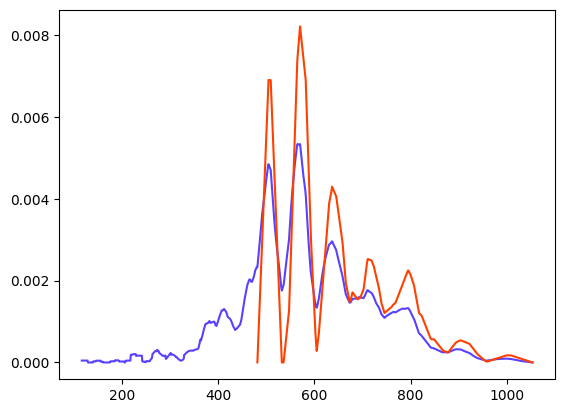

In [22]:
apex_rotations, apex_w = apex_arrow_rotation(time)
apex_pmf, apex_support = mixture_distribution(apex_rotations, apex_w)

plt.plot(apex_support, apex_pmf)
plt.plot(
    mode_rotation.unique_actions_distribution["Apex Arrow"]["support"],
    mode_rotation.unique_actions_distribution["Apex Arrow"]["dps_distribution"],
)

### HS

<Axes: xlabel='Damage per Second (DPS)'>

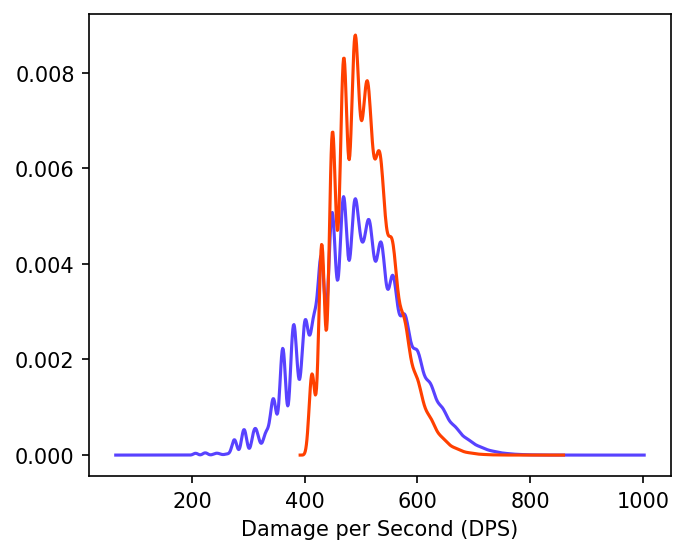

In [23]:
hs_w = [p_hs(n, 14) for n in range(1, 8)]
hs_rotations = [
    Rotation(
        pd.DataFrame(
            [
                make_action_record(
                    n,
                    8181,
                    "Heartbreak Shot",
                    "mb",
                    BARD_RATE.p,
                    BARD_RATE.l_c,
                    1.01,
                    False,
                )
            ]
        ),
        time,
        1,
        1,
        1,
        1,
    )
    for n in range(1, 8)
]
hs_pmf, hs_support = mixture_distribution(hs_rotations, hs_w)

hs_mode = Rotation(
    pd.DataFrame(
        [
            make_action_record(
                6,
                8181,
                "Heartbreak Shot",
                "mb",
                BARD_RATE.get_p(),
                BARD_RATE.l_c,
                1.01,
                False,
            ),
        ]
    ),
    time,
    1,
    1,
    1,
    1,
)

fig, ax = plt.subplots(1, 1, figsize=(5, 4), dpi=150)
plt.plot(hs_support, hs_pmf)
hs_mode.plot_rotation_distribution(ax=ax)


### Convolve

In [24]:
pd.DataFrame(deterministic_records)

,n,d2,action_name,base_action,p_n,p_c,p_d,p_cd,l_c,buffs,is_dot
0,1,3636,Attack-wm_bv_rf,Attack,0.36356,0.12444,0.38144,0.13056,1585.0,1.060,False
1,1,8181,Heartbreak Shot-wm_bv_rf,Heartbreak Shot,0.36356,0.12444,0.38144,0.13056,1585.0,1.060,False
2,6,3636,Attack-wm_bv_rf_rs,Attack,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
3,3,8181,Heartbreak Shot-wm_bv_rf_rs,Heartbreak Shot,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
4,2,11818,Empyreal Arrow-wm_bv_rf_rs,Empyreal Arrow,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
5,1,27272,Blast Arrow-wm_bv_rf_rs,Blast Arrow,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
6,1,4545,Iron Jaws-wm_bv_rf_rs,Iron Jaws,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
7,1,40909,Radiant Encore (3)-wm_bv_rf_rs,Radiant Encore (3),0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
8,1,27272,Resonant Arrow-wm_bv_rf_rs,Resonant Arrow,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False
9,1,18181,Sidewinder-wm_bv_rf_rs,Sidewinder,0.36356,0.12444,0.38144,0.13056,1585.0,1.219,False


In [25]:
deterministic_rotation = Rotation(pd.DataFrame(deterministic_records), time, 1, 1, 1, 1)

proc_pmf, proc_support = convolve_sequences(
    [
        (
            deterministic_rotation.rotation_dps_distribution,
            deterministic_rotation.rotation_dps_support,
        ),
        (ra_pmf, ra_supp),  # refulgent arrow
        (pp3_pmf, pp3_support),  # PP3
        (apex_pmf, apex_support),  # Apex
        (hs_pmf, hs_support),  # HS
    ]
)

## Finally, comparison

In [26]:
mode_mean = pmf_mean(
    mode_rotation.rotation_dps_support, mode_rotation.rotation_dps_distribution
)
mode_std = pmf_std(
    mode_rotation.rotation_dps_support, mode_rotation.rotation_dps_distribution
)

proc_mean = pmf_mean(proc_support, proc_pmf)
proc_std = pmf_std(proc_support, proc_pmf)

print(f"sigma % change: {(proc_std - mode_std) / mode_std:.1%}")

sigma % change: 9.3%


lol all that work for 9% variability

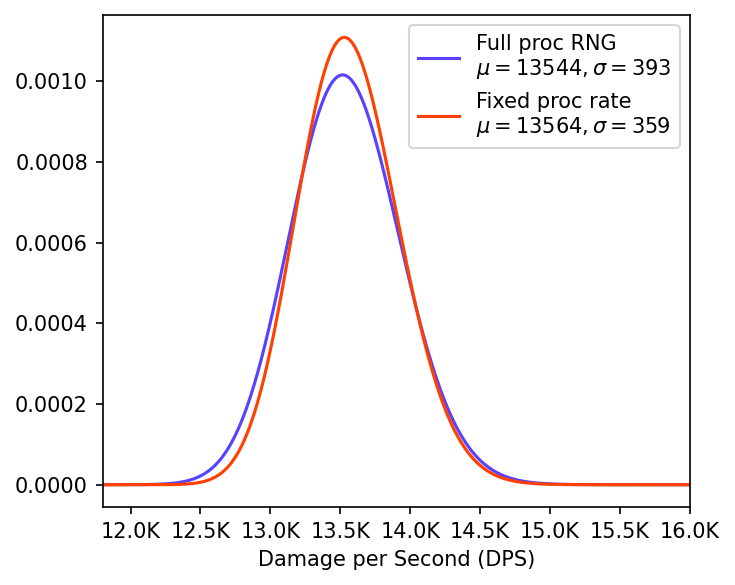

In [27]:
def thousands_formatter_1d(x, p):
    """Like thousands_formatter but with 1 decimal point"""
    if x >= 1000:
        return f"{x / 1000:.1f}K"
    return str(x)


fig, ax = plt.subplots(1, 1, figsize=(5, 4), dpi=150)

ax.plot(
    proc_support,
    proc_pmf,
    label="Full proc RNG\n" + rf"$\mu = {proc_mean:.0f}, \sigma={proc_std:.0f}$",
)

mode_rotation.plot_rotation_distribution(
    ax=ax,
    label="Fixed proc rate\n" + rf"$\mu = {mode_mean:.0f}, \sigma={mode_std:.0f}$",
)

ax.legend()
ax.xaxis.set_major_formatter(FuncFormatter(thousands_formatter_1d))
ax.set_xlim([11800, 16000])
plt.tight_layout()
plt.savefig("../tex/img/full-rotation.png")
plt.show()